**Taller 03: Análisis de Redes y Sistemas de Recomendación**

**Maestría en Ciencia de Datos**

Conjunto de datos: MovieLens 100K

Herramientas: Python, Google Colab, Pandas, NetworkX, Matplotlib y Scikit-Surprise.

**Introducción**

Los sistemas de recomendación permiten analizar las preferencias de los usuarios para sugerir productos, servicios o contenidos de acuerdo con patrones identificados en los datos.

En este trabajo se utiliza el conjunto MovieLens 100K para estudiar las relaciones entre usuarios y películas mediante teoría de grafos y desarrollar modelos de recomendación basados en filtrado colaborativo.

Se aplican técnicas de análisis de redes, detección de comunidades mediante Girvan-Newman y modelos predictivos SVD y KNN, evaluados mediante la métrica RMSE.

**Objetivo general**

Analizar las relaciones entre usuarios y películas mediante técnicas de teoría de grafos y desarrollar un sistema de recomendación que permita estimar las preferencias de los usuarios.

**Objetivos específicos**

Explorar y caracterizar el conjunto de datos MovieLens 100K.

Construir un grafo bipartito que represente las interacciones entre usuarios y películas.

Analizar propiedades de la red e identificar comunidades mediante Girvan-Newman.

Implementar y comparar modelos de recomendación SVD y KNN.

Optimizar los hiperparámetros de los modelos y generar recomendaciones personalizadas.

**1. Preparación del entorno de trabajo**

En esta etapa se verifica la versión de Python y la disponibilidad de las bibliotecas necesarias para desarrollar el análisis.

Se utilizan Pandas para manipular los datos, NetworkX para construir y analizar grafos, Matplotlib para generar visualizaciones y Scikit-Surprise para implementar los modelos de recomendación.

El trabajo se desarrolla en Google Colab, que permite ejecutar código Python sin necesidad de configurar todas las dependencias en un entorno local.

In [1]:
import sys
import pandas as pd
import networkx as nx
import matplotlib
import sklearn

print("Python:", sys.version.split()[0])
print("Pandas:", pd.__version__)
print("NetworkX:", nx.__version__)
print("Matplotlib:", matplotlib.__version__)
print("Scikit-learn:", sklearn.__version__)

Python: 3.13.16
Pandas: 2.2.3
NetworkX: 3.7
Matplotlib: 3.10.0
Scikit-learn: 1.6.1


In [2]:
import urllib.request
import zipfile
import os

# Descargar el conjunto de datos MovieLens 100K
url = "https://files.grouplens.org/datasets/movielens/ml-100k.zip"

urllib.request.urlretrieve(url, "ml-100k.zip")

# Descomprimir los archivos
with zipfile.ZipFile("ml-100k.zip", "r") as zip_ref:
    zip_ref.extractall(".")

# Comprobar que se descargó correctamente
print("Archivos descargados:")
print(os.listdir("ml-100k"))

Archivos descargados:
['u.occupation', 'u4.base', 'u5.test', 'u3.base', 'ua.base', 'mku.sh', 'ub.base', 'u1.test', 'u4.test', 'u5.base', 'u.user', 'u.item', 'u.data', 'u2.base', 'u1.base', 'ub.test', 'u.genre', 'ua.test', 'u.info', 'allbut.pl', 'README', 'u3.test', 'u2.test']


**2. Carga y exploración del conjunto de datos**
Se utiliza MovieLens 100K, un conjunto de datos que contiene 100.000 calificaciones realizadas por 943 usuarios sobre 1.682 películas.

Inicialmente se cargan los registros y se examinan sus principales características, incluyendo el número de usuarios, películas, calificaciones y valores faltantes.

Este procedimiento permite verificar la integridad de los datos antes de construir la red y entrenar los modelos de recomendación.

In [3]:
import pandas as pd

# Definir los nombres de las columnas
columnas = ["usuario_id", "pelicula_id", "calificacion", "timestamp"]

# Cargar las calificaciones de MovieLens
datos = pd.read_csv(
    "ml-100k/u.data",
    sep="\t",
    names=columnas
)

# Mostrar las primeras 5 filas
datos.head()

,usuario_id,pelicula_id,calificacion,timestamp
0,196,242,3,881250949
1,186,302,3,891717742
2,22,377,1,878887116
3,244,51,2,880606923
4,166,346,1,886397596


In [4]:
# Exploración inicial del conjunto de datos

print("Total de calificaciones:", len(datos))

print("Total de usuarios:",
      datos["usuario_id"].nunique())

print("Total de películas:",
      datos["pelicula_id"].nunique())

print("\nValores faltantes:")
print(datos.isnull().sum())

print("\nEstadísticas de las calificaciones:")
print(datos["calificacion"].describe())

Total de calificaciones: 100000
Total de usuarios: 943
Total de películas: 1682

Valores faltantes:
usuario_id      0
pelicula_id     0
calificacion    0
timestamp       0
dtype: int64

Estadísticas de las calificaciones:
count    100000.000000
mean          3.529860
std           1.125674
min           1.000000
25%           3.000000
50%           4.000000
75%           4.000000
max           5.000000
Name: calificacion, dtype: float64


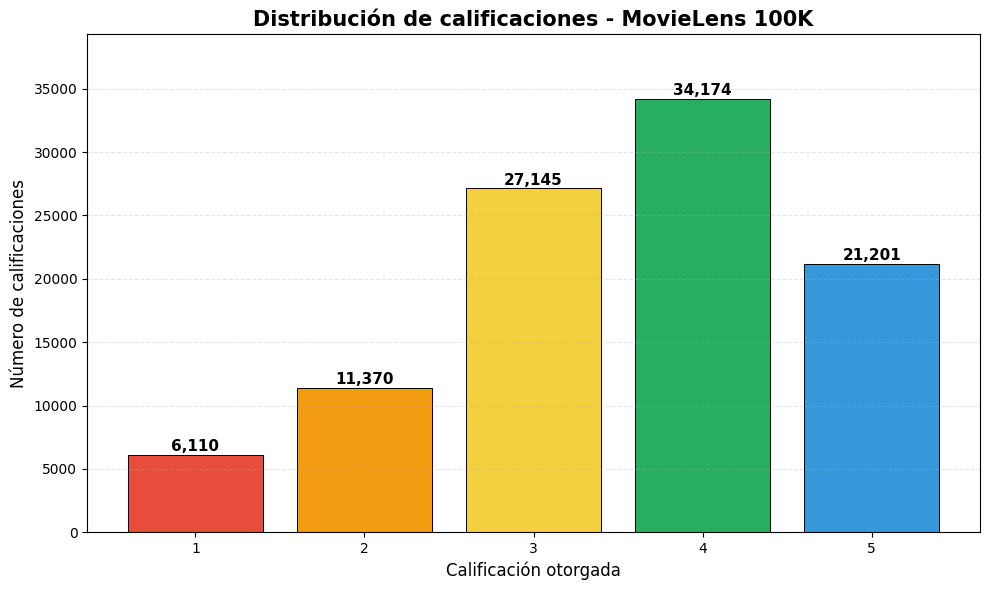

In [5]:
import matplotlib.pyplot as plt

# Contar cuántas veces aparece cada calificación
conteo_calificaciones = datos["calificacion"].value_counts().sort_index()

# Definir colores para cada calificación
colores = [
    "#E74C3C",  # 1 estrella: rojo
    "#F39C12",  # 2 estrellas: naranja
    "#F4D03F",  # 3 estrellas: amarillo
    "#27AE60",  # 4 estrellas: verde
    "#3498DB"   # 5 estrellas: azul
]

# Crear gráfico de barras
plt.figure(figsize=(10, 6))

barras = plt.bar(
    conteo_calificaciones.index,
    conteo_calificaciones.values,
    color=colores,
    edgecolor="black",
    linewidth=0.7
)

# Mostrar cantidades encima de cada barra
for barra in barras:
    altura = barra.get_height()

    plt.text(
        barra.get_x() + barra.get_width() / 2,
        altura + 300,
        f"{int(altura):,}",
        ha="center",
        fontsize=11,
        fontweight="bold"
    )

# Personalizar gráfica
plt.title(
    "Distribución de calificaciones - MovieLens 100K",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Calificación otorgada", fontsize=12)
plt.ylabel("Número de calificaciones", fontsize=12)

plt.xticks([1, 2, 3, 4, 5])
plt.ylim(0, conteo_calificaciones.max() * 1.15)

plt.grid(axis="y", linestyle="--", alpha=0.3)
plt.tight_layout()
plt.show()

Interpretación de la distribución de calificaciones

El análisis exploratorio de MovieLens 100K permitió identificar que la calificación más frecuente fue 4, con 34.174 registros, equivalente al 34,17 % del conjunto de datos.

Asimismo, el 55,38 % de las calificaciones correspondió a puntuaciones de 4 y 5, evidenciando una mayor concentración de valoraciones positivas.

Estos resultados permiten comprender la distribución de las preferencias registradas y proporcionan un contexto importante para el entrenamiento y la evaluación de los modelos de recomendación SVD y KNN.

**3. Construcción del grafo bipartito**

Se construye una red bipartita utilizando NetworkX, donde los nodos representan dos tipos de entidades: usuarios y películas.

Las aristas representan las interacciones registradas cuando un usuario califica una película.

Esta representación permite analizar la estructura de las relaciones entre usuarios y películas, identificar los nodos con mayor actividad y explorar las conexiones de la red mediante algoritmos de teoría de grafos.

In [6]:
import networkx as nx

# Crear un grafo vacío
G = nx.Graph()

# Agregar los usuarios como nodos
for usuario in datos["usuario_id"].unique():
    G.add_node(f"U_{usuario}", bipartite=0)

# Agregar las películas como nodos
for pelicula in datos["pelicula_id"].unique():
    G.add_node(f"P_{pelicula}", bipartite=1)

# Crear conexiones entre usuarios y películas
for fila in datos.itertuples(index=False):
    G.add_edge(
        f"U_{fila.usuario_id}",
        f"P_{fila.pelicula_id}",
        weight=fila.calificacion
    )

# Mostrar información del grafo
print("Total de nodos:", G.number_of_nodes())
print("Total de aristas:", G.number_of_edges())
print("¿Es un grafo bipartito?:", nx.is_bipartite(G))

Total de nodos: 2625
Total de aristas: 100000
¿Es un grafo bipartito?: True


**4 Análisis de centralidad de grado**.

Se calcula el grado de los nodos para identificar los usuarios más activos y las películas más populares de MovieLens 100K.

El grado de un usuario representa la cantidad de películas que ha calificado, mientras que el grado de una película indica cuántos usuarios la han evaluado.

Este análisis permite identificar los nodos con mayor número de conexiones dentro de la red bipartita.

In [7]:
# Calcular cuántas películas calificó cada usuario
grados_usuarios = {}

for usuario in datos["usuario_id"].unique():
    nodo = f"U_{usuario}"
    grados_usuarios[usuario] = G.degree(nodo)

# Ordenar los usuarios de mayor a menor actividad
usuarios_ordenados = sorted(
    grados_usuarios.items(),
    key=lambda x: x[1],
    reverse=True
)

# Mostrar los cinco usuarios más activos
print("TOP 5 USUARIOS MÁS ACTIVOS")

for usuario, cantidad in usuarios_ordenados[:5]:
    print(f"Usuario {usuario}: {cantidad} películas calificadas")

TOP 5 USUARIOS MÁS ACTIVOS
Usuario 405: 737 películas calificadas
Usuario 655: 685 películas calificadas
Usuario 13: 636 películas calificadas
Usuario 450: 540 películas calificadas
Usuario 276: 518 películas calificadas


In [8]:
# Cargar información de las películas
peliculas = pd.read_csv(
    "ml-100k/u.item",
    sep="|",
    encoding="latin-1",
    header=None,
    usecols=[0, 1],
    names=["pelicula_id", "titulo"]
)

peliculas.head()

,pelicula_id,titulo
0,1,Toy Story (1995)
1,2,GoldenEye (1995)
2,3,Four Rooms (1995)
3,4,Get Shorty (1995)
4,5,Copycat (1995)


In [9]:
# Calcular el grado de cada película
grados_peliculas = {}

for pelicula in datos["pelicula_id"].unique():
    nodo = f"P_{pelicula}"
    grados_peliculas[pelicula] = G.degree(nodo)

# Ordenar de mayor a menor centralidad
peliculas_ordenadas = sorted(
    grados_peliculas.items(),
    key=lambda x: x[1],
    reverse=True
)

# Convertir los resultados en una tabla
top_peliculas = pd.DataFrame(
    peliculas_ordenadas[:10],
    columns=["pelicula_id", "numero_calificaciones"]
)

# Incorporar los títulos
top_peliculas = top_peliculas.merge(
    peliculas,
    on="pelicula_id",
    how="left"
)

top_peliculas[
    ["titulo", "numero_calificaciones"]
]

,titulo,numero_calificaciones
0,Star Wars (1977),583
1,Contact (1997),509
2,Fargo (1996),508
3,Return of the Jedi (1983),507
4,Liar Liar (1997),485
5,"English Patient, The (1996)",481
6,Scream (1996),478
7,Toy Story (1995),452
8,Air Force One (1997),431
9,Independence Day (ID4) (1996),429


**5. Coeficiente de agrupamiento bipartito**

Se calcula el coeficiente de agrupamiento bipartito para estudiar el solapamiento de conexiones entre usuarios y películas.

Debido a que la red es bipartita, se utiliza una medida adaptada a esta estructura, en lugar del coeficiente tradicional basado en triángulos.

En una muestra de 20 usuarios se obtuvo un coeficiente promedio de 0,1013, que indica un solapamiento relativamente bajo según esta medida. Este resultado corresponde únicamente a la muestra analizada.

In [10]:
from networkx.algorithms import bipartite

# Seleccionar los nodos correspondientes a usuarios
nodos_usuarios = [
    nodo for nodo, atributos in G.nodes(data=True)
    if atributos["bipartite"] == 0
]

# Calcular el agrupamiento bipartito para 20 usuarios
muestra_usuarios = nodos_usuarios[:20]

agrupamiento = bipartite.clustering(
    G,
    nodes=muestra_usuarios
)

# Mostrar los resultados
print("COEFICIENTE DE AGRUPAMIENTO BIPARTITO")

for usuario, valor in agrupamiento.items():
    print(f"{usuario}: {valor:.4f}")

print("\nPromedio de la muestra:",
      sum(agrupamiento.values()) / len(agrupamiento))

COEFICIENTE DE AGRUPAMIENTO BIPARTITO
U_196: 0.0487
U_186: 0.0807
U_22: 0.0921
U_244: 0.1066
U_166: 0.0745
U_298: 0.1187
U_115: 0.0971
U_253: 0.1059
U_305: 0.1249
U_6: 0.1255
U_62: 0.1286
U_286: 0.1055
U_200: 0.1177
U_210: 0.1129
U_224: 0.0761
U_303: 0.1186
U_122: 0.0520
U_194: 0.1282
U_291: 0.0999
U_234: 0.1118

Promedio de la muestra: 0.10129308098246874


**6. Detección y visualización de comunidades**

Se aplica el algoritmo Girvan-Newman para explorar la estructura de comunidades en una subred de MovieLens 100K.

Debido al costo computacional de aplicar este algoritmo a toda la red, se selecciona una subred de 44 nodos y 295 aristas.

En la segunda división se identifican tres comunidades de 42, 1 y 1 nodos. Estos resultados muestran una comunidad predominante y dos nodos periféricos separados progresivamente.

Las comunidades se visualizan mediante colores diferentes, mientras que las formas permiten distinguir usuarios y películas.

In [11]:
from networkx.algorithms.community import girvan_newman

# Seleccionar 30 usuarios
usuarios_muestra = datos["usuario_id"].unique()[:30]

# Obtener sus calificaciones
datos_muestra = datos[
    datos["usuario_id"].isin(usuarios_muestra)
]

# Seleccionar las 15 películas más calificadas
peliculas_muestra = (
    datos_muestra["pelicula_id"]
    .value_counts()
    .head(15)
    .index
)

# Filtrar las interacciones
datos_comunidad = datos_muestra[
    datos_muestra["pelicula_id"].isin(peliculas_muestra)
]

# Construir una subred
G_comunidad = nx.Graph()

for fila in datos_comunidad.itertuples(index=False):
    G_comunidad.add_edge(
        f"U_{fila.usuario_id}",
        f"P_{fila.pelicula_id}"
    )

print("Nodos de la subred:", G_comunidad.number_of_nodes())
print("Aristas de la subred:", G_comunidad.number_of_edges())

# Aplicar Girvan-Newman: primera división
comunidades_generador = girvan_newman(G_comunidad)
comunidades = next(comunidades_generador)

print("\nComunidades detectadas:", len(comunidades))

for i, comunidad in enumerate(comunidades, start=1):
    print(f"Comunidad {i}: {len(comunidad)} nodos")

Nodos de la subred: 44
Aristas de la subred: 295

Comunidades detectadas: 2
Comunidad 1: 43 nodos
Comunidad 2: 1 nodos


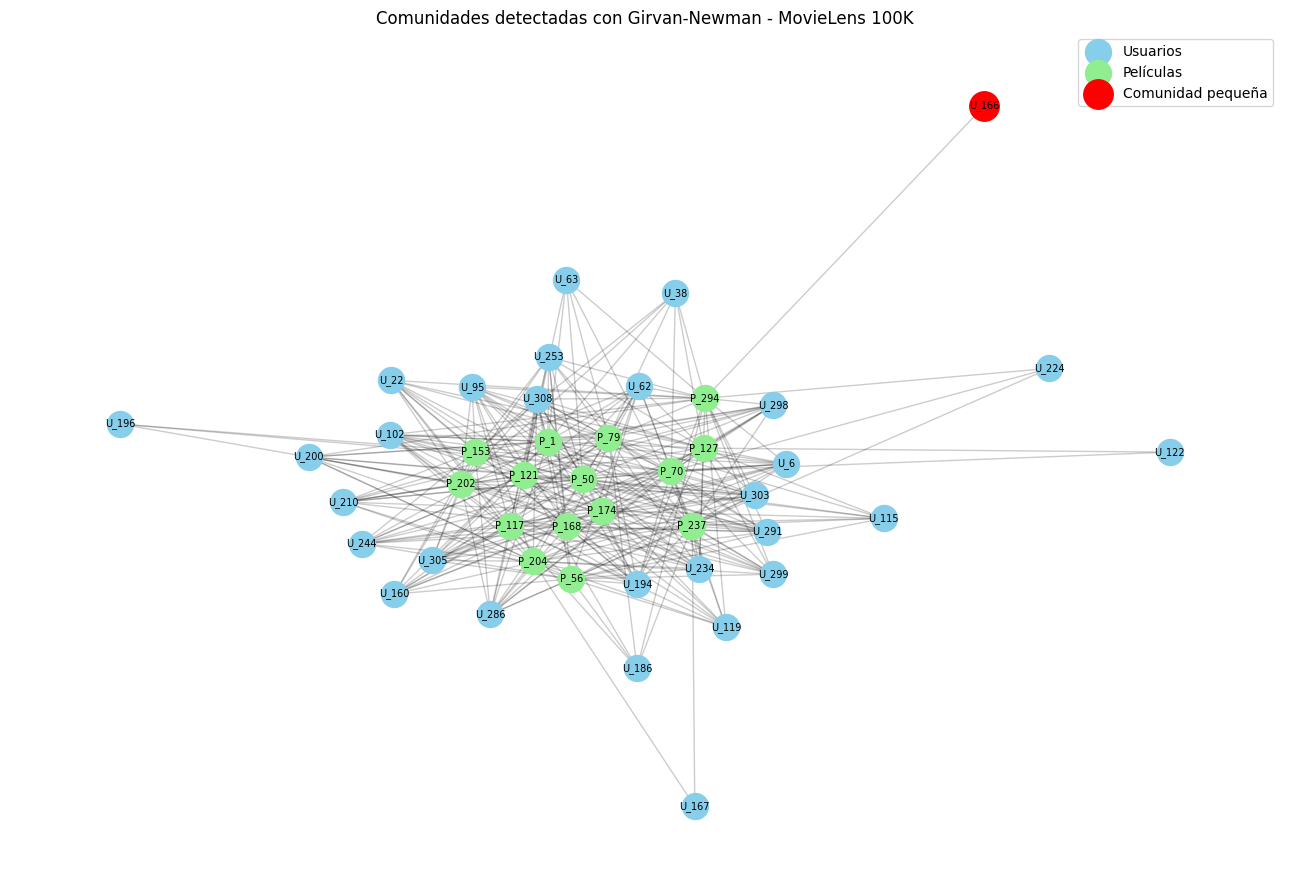

In [12]:
import matplotlib.pyplot as plt
import networkx as nx

# Crear posiciones de los nodos
pos = nx.spring_layout(G_comunidad, seed=42)

# Identificar usuarios y películas
usuarios = [
    n for n in G_comunidad.nodes()
    if n.startswith("U_")
]

peliculas_nodos = [
    n for n in G_comunidad.nodes()
    if n.startswith("P_")
]

# Identificar la comunidad más pequeña
comunidad_pequena = min(comunidades, key=len)

# Crear gráfico
plt.figure(figsize=(13, 9))

# Dibujar conexiones
nx.draw_networkx_edges(
    G_comunidad,
    pos,
    alpha=0.2
)

# Dibujar usuarios
nx.draw_networkx_nodes(
    G_comunidad,
    pos,
    nodelist=usuarios,
    node_color="skyblue",
    node_size=350,
    label="Usuarios"
)

# Dibujar películas
nx.draw_networkx_nodes(
    G_comunidad,
    pos,
    nodelist=peliculas_nodos,
    node_color="lightgreen",
    node_size=350,
    label="Películas"
)

# Resaltar comunidad pequeña
nx.draw_networkx_nodes(
    G_comunidad,
    pos,
    nodelist=list(comunidad_pequena),
    node_color="red",
    node_size=450,
    label="Comunidad pequeña"
)

# Agregar etiquetas
nx.draw_networkx_labels(
    G_comunidad,
    pos,
    font_size=7
)

plt.title("Comunidades detectadas con Girvan-Newman - MovieLens 100K")
plt.legend()
plt.axis("off")
plt.tight_layout()
plt.show()

In [13]:
# Obtener las dos primeras divisiones de Girvan-Newman
generador = girvan_newman(G_comunidad)

primera_division = next(generador)
segunda_division = next(generador)

# Mostrar las comunidades de la segunda división
print("SEGUNDA DIVISIÓN DE GIRVAN-NEWMAN")
print("Número de comunidades:", len(segunda_division))

for i, comunidad in enumerate(segunda_division, start=1):
    print(f"Comunidad {i}: {len(comunidad)} nodos")

SEGUNDA DIVISIÓN DE GIRVAN-NEWMAN
Número de comunidades: 3
Comunidad 1: 42 nodos
Comunidad 2: 1 nodos
Comunidad 3: 1 nodos


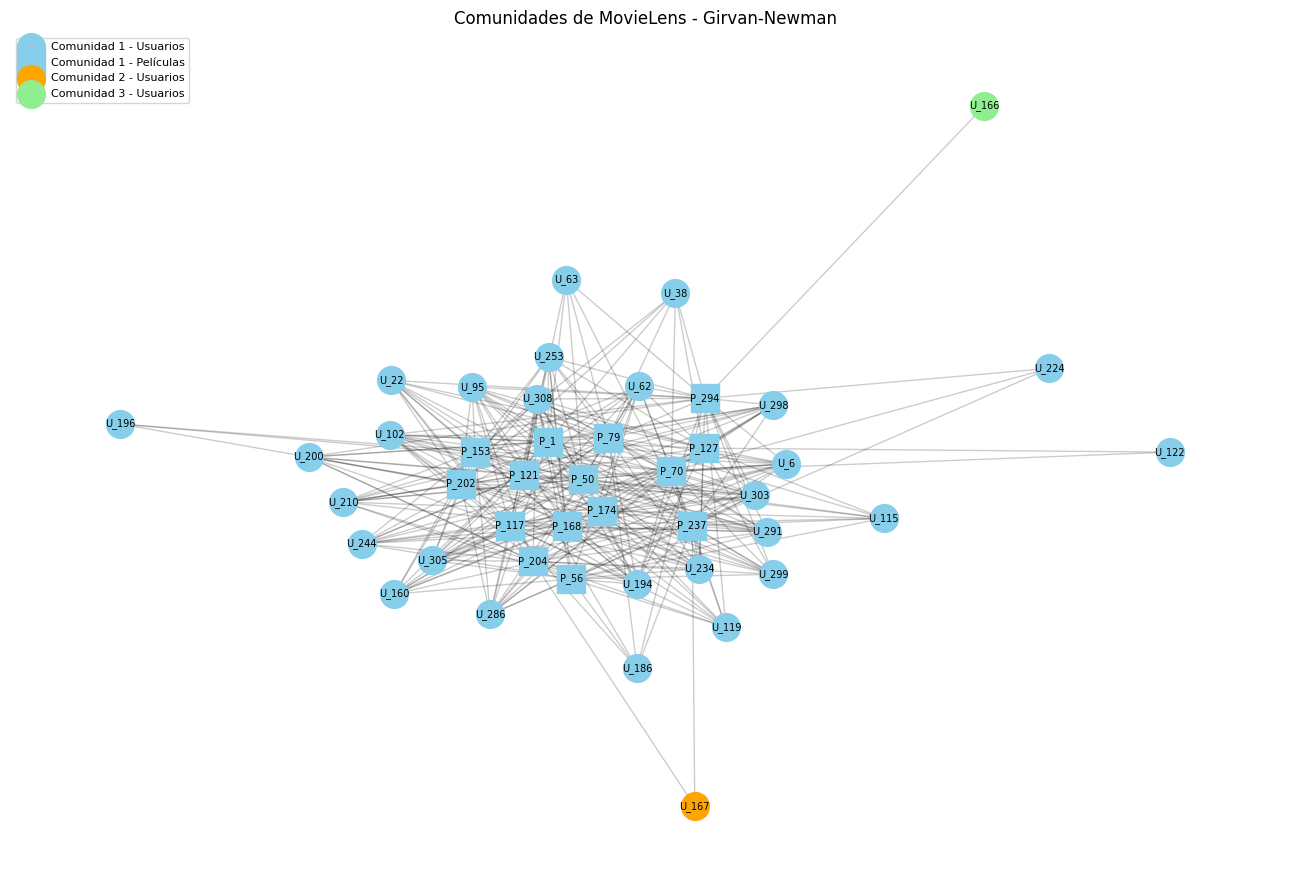

In [14]:
import matplotlib.pyplot as plt
import networkx as nx

# Utilizar las comunidades de la segunda división
comunidades_finales = list(segunda_division)

# Definir colores para las comunidades
colores = ["skyblue", "orange", "lightgreen"]

# Calcular posiciones de los nodos
pos = nx.spring_layout(G_comunidad, seed=42)

plt.figure(figsize=(13, 9))

# Dibujar las conexiones
nx.draw_networkx_edges(
    G_comunidad,
    pos,
    alpha=0.2
)

# Dibujar cada comunidad con un color diferente
for i, comunidad in enumerate(comunidades_finales):

    usuarios_comunidad = [
        n for n in comunidad if n.startswith("U_")
    ]

    peliculas_comunidad = [
        n for n in comunidad if n.startswith("P_")
    ]

    nx.draw_networkx_nodes(
        G_comunidad,
        pos,
        nodelist=usuarios_comunidad,
        node_color=colores[i],
        node_shape="o",
        node_size=400,
        label=f"Comunidad {i+1} - Usuarios"
    )

    nx.draw_networkx_nodes(
        G_comunidad,
        pos,
        nodelist=peliculas_comunidad,
        node_color=colores[i],
        node_shape="s",
        node_size=400,
        label=f"Comunidad {i+1} - Películas"
    )

# Mostrar identificadores
nx.draw_networkx_labels(
    G_comunidad,
    pos,
    font_size=7
)

plt.title("Comunidades de MovieLens - Girvan-Newman")
plt.legend(loc="upper left", fontsize=8)
plt.axis("off")
plt.tight_layout()
plt.show()

In [15]:
%pip install scikit-surprise


**7. Implementación de modelos de recomendación**

Se implementan dos algoritmos de filtrado colaborativo utilizando la biblioteca Scikit-Surprise.

SVD (Singular Value Decomposition): utiliza factores latentes para representar las preferencias de los usuarios y las características de las películas, permitiendo estimar calificaciones que todavía no se han realizado.

KNN (K-Nearest Neighbors): utiliza la similitud entre usuarios para predecir las calificaciones a partir de las preferencias de usuarios similares.

Los datos se dividen en un 80 % para entrenamiento y un 20 % para prueba, utilizando una semilla aleatoria de 42 para facilitar la reproducibilidad.

In [16]:
from surprise import Dataset, Reader, SVD, KNNBasic, accuracy
from surprise.model_selection import train_test_split

# Definir la escala de calificaciones
reader = Reader(rating_scale=(1, 5))

# Seleccionar las columnas necesarias
datos_recomendacion = datos[
    ["usuario_id", "pelicula_id", "calificacion"]
]

# Convertir los datos al formato de Surprise
dataset = Dataset.load_from_df(
    datos_recomendacion,
    reader
)

# Dividir los datos en entrenamiento y prueba
trainset, testset = train_test_split(
    dataset,
    test_size=0.2,
    random_state=42
)

print("Surprise funciona correctamente")
print("Calificaciones de entrenamiento:", trainset.n_ratings)
print("Calificaciones de prueba:", len(testset))

Surprise funciona correctamente
Calificaciones de entrenamiento: 80000
Calificaciones de prueba: 20000


**8. Evaluación inicial de los modelos**

Se entrenan los modelos SVD y KNN utilizando los datos de entrenamiento y posteriormente se evalúan sus predicciones mediante RMSE.

Esta métrica permite cuantificar el error entre las calificaciones reales y las estimadas. Cuanto menor sea el RMSE, mejor será el desempeño predictivo del modelo.

En la evaluación inicial, SVD obtuvo un RMSE de 0,9352 y KNN de 1,0194, por lo que SVD presentó mejores resultados en este experimento.

In [17]:
# Crear el modelo SVD
modelo_svd = SVD(
    n_factors=100,
    n_epochs=20,
    random_state=42
)

# Entrenar el modelo
modelo_svd.fit(trainset)

# Predecir las calificaciones del conjunto de prueba
predicciones_svd = modelo_svd.test(testset)

# Calcular el error RMSE
print("RESULTADOS DEL MODELO SVD")
rmse_svd = accuracy.rmse(predicciones_svd)

RESULTADOS DEL MODELO SVD
RMSE: 0.9352


In [18]:
# Configurar el modelo KNN basado en usuarios
sim_options = {
    "name": "cosine",
    "user_based": True
}

# Crear el modelo KNN
modelo_knn = KNNBasic(
    k=40,
    sim_options=sim_options,
    verbose=False
)

# Entrenar el modelo
modelo_knn.fit(trainset)

# Realizar predicciones
predicciones_knn = modelo_knn.test(testset)

# Calcular RMSE
print("RESULTADOS DEL MODELO KNN")
rmse_knn = accuracy.rmse(predicciones_knn)

RESULTADOS DEL MODELO KNN
RMSE: 1.0194


In [19]:
# Crear tabla comparativa
comparacion = pd.DataFrame({
    "Modelo": ["SVD", "KNN"],
    "RMSE": [rmse_svd, rmse_knn]
})

# Ordenar del menor al mayor error
comparacion = comparacion.sort_values("RMSE")

print("COMPARACIÓN DE MODELOS")
print(comparacion.to_string(index=False))

# Identificar el modelo con menor error
mejor_modelo = comparacion.iloc[0]

print("\nModelo con menor RMSE:", mejor_modelo["Modelo"])
print("RMSE:", round(mejor_modelo["RMSE"], 4))

COMPARACIÓN DE MODELOS
Modelo     RMSE
   SVD 0.935171
   KNN 1.019354

Modelo con menor RMSE: SVD
RMSE: 0.9352


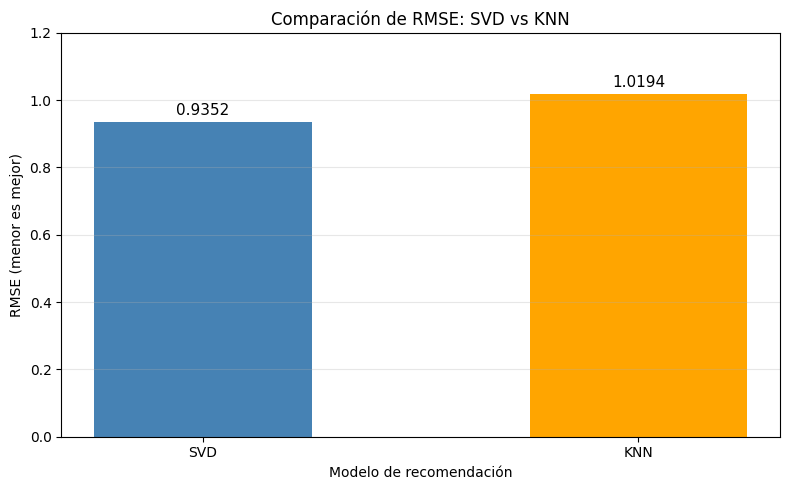

In [20]:
import matplotlib.pyplot as plt

# Modelos y resultados obtenidos
modelos = ["SVD", "KNN"]
errores = [rmse_svd, rmse_knn]

# Crear gráfico
plt.figure(figsize=(8, 5))

barras = plt.bar(
    modelos,
    errores,
    color=["steelblue", "orange"],
    width=0.5
)

# Mostrar el RMSE sobre cada barra
for barra, valor in zip(barras, errores):
    plt.text(
        barra.get_x() + barra.get_width()/2,
        barra.get_height() + 0.02,
        f"{valor:.4f}",
        ha="center",
        fontsize=11
    )

plt.title("Comparación de RMSE: SVD vs KNN")
plt.xlabel("Modelo de recomendación")
plt.ylabel("RMSE (menor es mejor)")
plt.ylim(0, 1.2)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

**9. Optimización de hiperparámetros mediante GridSearchCV**.

Se utiliza GridSearchCV para evaluar diferentes combinaciones de hiperparámetros y seleccionar las configuraciones con mejor rendimiento.

La búsqueda se realiza sobre los datos de entrenamiento mediante validación cruzada, utilizando RMSE como criterio de evaluación.

Posteriormente, los modelos optimizados se evalúan sobre el conjunto de prueba reservado para comparar su rendimiento con las versiones iniciales.

In [21]:
from surprise.model_selection import GridSearchCV
from surprise import Dataset, SVD

# Convertir únicamente los datos de entrenamiento
datos_train = pd.DataFrame(
    trainset.build_testset(),
    columns=["usuario_id", "pelicula_id", "calificacion"]
)

dataset_train = Dataset.load_from_df(
    datos_train,
    reader
)

# Definir hiperparámetros que vamos a probar
parametros_svd = {
    "n_factors": [50, 100, 150],
    "n_epochs": [20, 30],
    "lr_all": [0.005],
    "reg_all": [0.02]
}

# Crear búsqueda de hiperparámetros
grid_svd = GridSearchCV(
    SVD,
    parametros_svd,
    measures=["rmse"],
    cv=3,
    n_jobs=-1
)

# Ejecutar búsqueda
grid_svd.fit(dataset_train)

# Mostrar resultados
print("MEJOR RMSE EN VALIDACIÓN CRUZADA:")
print(grid_svd.best_score["rmse"])

print("\nMEJORES HIPERPARÁMETROS:")
print(grid_svd.best_params["rmse"])

MEJOR RMSE EN VALIDACIÓN CRUZADA:
0.9513674844933874

MEJORES HIPERPARÁMETROS:
{'n_factors': 50, 'n_epochs': 20, 'lr_all': 0.005, 'reg_all': 0.02}


In [22]:
# Crear SVD con los mejores hiperparámetros
modelo_svd_optimizado = SVD(
    **grid_svd.best_params["rmse"],
    random_state=42
)

# Entrenar con las 80.000 calificaciones
modelo_svd_optimizado.fit(trainset)

# Predecir sobre las 20.000 calificaciones de prueba
predicciones_svd_opt = modelo_svd_optimizado.test(testset)

# Calcular RMSE
rmse_svd_opt = accuracy.rmse(predicciones_svd_opt)

# Comparar SVD original y optimizado
print("\nCOMPARACIÓN DE SVD")
print(f"SVD original: {rmse_svd:.4f}")
print(f"SVD optimizado: {rmse_svd_opt:.4f}")

if rmse_svd_opt < rmse_svd:
    print("La configuración optimizada obtuvo menor RMSE.")
else:
    print("La configuración optimizada no mejoró el RMSE de prueba.")

RMSE: 0.9348

COMPARACIÓN DE SVD
SVD original: 0.9352
SVD optimizado: 0.9348
La configuración optimizada obtuvo menor RMSE.


In [23]:
from surprise.model_selection import GridSearchCV
from surprise import KNNBasic

# Configuraciones que vamos a evaluar
parametros_knn = {
    "k": [20, 40, 60],
    "min_k": [1],
    "sim_options": {
        "name": ["cosine", "msd"],
        "user_based": [True]
    }
}

# Crear búsqueda de hiperparámetros
grid_knn = GridSearchCV(
    KNNBasic,
    parametros_knn,
    measures=["rmse"],
    cv=3,
    n_jobs=-1,
    joblib_verbose=0
)

# Buscar la mejor configuración
grid_knn.fit(dataset_train)

# Mostrar resultados
print("MEJOR RMSE DE KNN EN VALIDACIÓN CRUZADA:")
print(grid_knn.best_score["rmse"])

print("\nMEJORES HIPERPARÁMETROS DE KNN:")
print(grid_knn.best_params["rmse"])

MEJOR RMSE DE KNN EN VALIDACIÓN CRUZADA:
1.0016888097038976

MEJORES HIPERPARÁMETROS DE KNN:
{'k': 40, 'min_k': 1, 'sim_options': {'name': 'msd', 'user_based': True}}


In [24]:
# Crear KNN con los mejores hiperparámetros
modelo_knn_optimizado = KNNBasic(
    **grid_knn.best_params["rmse"],
    verbose=False
)

# Entrenar con las 80.000 calificaciones
modelo_knn_optimizado.fit(trainset)

# Predecir sobre las 20.000 calificaciones de prueba
predicciones_knn_opt = modelo_knn_optimizado.test(testset)

# Calcular RMSE
rmse_knn_opt = accuracy.rmse(predicciones_knn_opt)

# Comparar resultados
print("\nCOMPARACIÓN DE KNN")
print(f"KNN original: {rmse_knn:.4f}")
print(f"KNN optimizado: {rmse_knn_opt:.4f}")

if rmse_knn_opt < rmse_knn:
    print("La configuración optimizada obtuvo menor RMSE.")
elif rmse_knn_opt > rmse_knn:
    print("La configuración optimizada no mejoró el RMSE de prueba.")
else:
    print("Ambas configuraciones obtuvieron el mismo RMSE.")

RMSE: 0.9802

COMPARACIÓN DE KNN
KNN original: 1.0194
KNN optimizado: 0.9802
La configuración optimizada obtuvo menor RMSE.


COMPARACIÓN FINAL DE MODELOS
Modelo Configuracion     RMSE
   SVD      Original 0.935171
   SVD    Optimizado 0.934761
   KNN      Original 1.019354
   KNN    Optimizado 0.980151


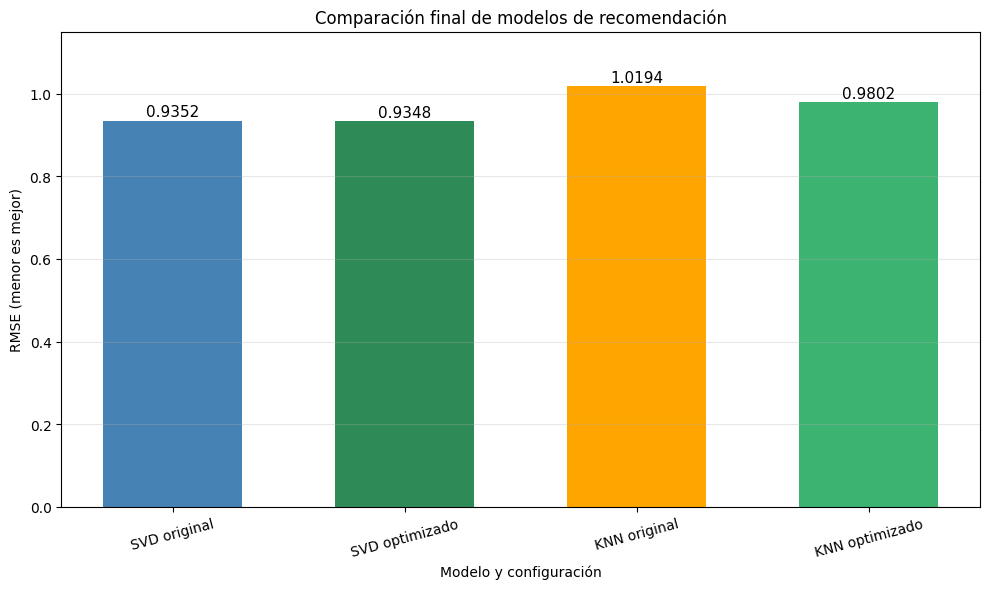


MEJOR MODELO:
SVD - Optimizado
RMSE: 0.9348


In [25]:
import pandas as pd
import matplotlib.pyplot as plt

# Organizar los resultados
resultados_finales = pd.DataFrame({
    "Modelo": ["SVD", "SVD", "KNN", "KNN"],
    "Configuracion": [
        "Original", "Optimizado",
        "Original", "Optimizado"
    ],
    "RMSE": [
        rmse_svd,
        rmse_svd_opt,
        rmse_knn,
        rmse_knn_opt
    ]
})

# Mostrar tabla
print("COMPARACIÓN FINAL DE MODELOS")
print(resultados_finales.to_string(index=False))

# Crear gráfico
plt.figure(figsize=(10, 6))

etiquetas = [
    "SVD original",
    "SVD optimizado",
    "KNN original",
    "KNN optimizado"
]

colores = [
    "steelblue",
    "seagreen",
    "orange",
    "mediumseagreen"
]

barras = plt.bar(
    etiquetas,
    resultados_finales["RMSE"],
    color=colores,
    width=0.6
)

# Mostrar valores sobre las barras
for barra, valor in zip(barras, resultados_finales["RMSE"]):
    plt.text(
        barra.get_x() + barra.get_width() / 2,
        barra.get_height() + 0.01,
        f"{valor:.4f}",
        ha="center",
        fontsize=11
    )

plt.title("Comparación final de modelos de recomendación")
plt.xlabel("Modelo y configuración")
plt.ylabel("RMSE (menor es mejor)")
plt.ylim(0, 1.15)
plt.grid(axis="y", alpha=0.3)
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

# Identificar el mejor modelo
mejor = resultados_finales.loc[
    resultados_finales["RMSE"].idxmin()
]

print("\nMEJOR MODELO:")
print(mejor["Modelo"], "-", mejor["Configuracion"])
print("RMSE:", round(mejor["RMSE"], 4))

**10. Generación de recomendaciones personalizadas**

Se utiliza el algoritmo SVD para generar recomendaciones personalizadas al usuario 196.

Para ello, se entrena el modelo final con el conjunto completo de calificaciones disponibles. Posteriormente, se identifican las películas que el usuario todavía no ha calificado y se estiman sus posibles puntuaciones.

Finalmente, se seleccionan las cinco películas con mayor calificación estimada y se visualizan mediante una gráfica de barras horizontales.

In [26]:
# PASO 25: Generar recomendaciones con SVD

from surprise import SVD

# Entrenar el modelo final con todos los datos
trainset_completo = dataset.build_full_trainset()

modelo_final = SVD(
    **grid_svd.best_params["rmse"],
    random_state=42
)

modelo_final.fit(trainset_completo)

# Seleccionar un usuario existente
usuario_elegido = 196

# Identificar películas que ya calificó
peliculas_calificadas = set(
    datos.loc[
        datos["usuario_id"] == usuario_elegido,
        "pelicula_id"
    ]
)

# Identificar todas las películas del catálogo
todas_peliculas = set(
    peliculas["pelicula_id"]
)

# Obtener películas todavía no calificadas
peliculas_pendientes = (
    todas_peliculas - peliculas_calificadas
)

# Predecir la calificación de cada película pendiente
recomendaciones = []

for pelicula_id in peliculas_pendientes:
    prediccion = modelo_final.predict(
        usuario_elegido,
        pelicula_id
    )

    recomendaciones.append({
        "pelicula_id": pelicula_id,
        "calificacion_estimada": prediccion.est
    })

# Ordenar de mayor a menor calificación estimada
recomendaciones_df = pd.DataFrame(recomendaciones)

recomendaciones_df = recomendaciones_df.sort_values(
    "calificacion_estimada",
    ascending=False
).head(5)

# Incorporar títulos de películas
top_5_recomendaciones = recomendaciones_df.merge(
    peliculas[["pelicula_id", "titulo"]],
    on="pelicula_id",
    how="left"
)

print("TOP 5 PELÍCULAS RECOMENDADAS")
print("Usuario:", usuario_elegido)

display(
    top_5_recomendaciones[
        ["titulo", "calificacion_estimada"]
    ]
)

TOP 5 PELÍCULAS RECOMENDADAS
Usuario: 196


,titulo,calificacion_estimada
0,"Close Shave, A (1995)",4.657331
1,"Wrong Trousers, The (1993)",4.651743
2,"Usual Suspects, The (1995)",4.482237
3,Rear Window (1954),4.439265
4,"Shawshank Redemption, The (1994)",4.399599


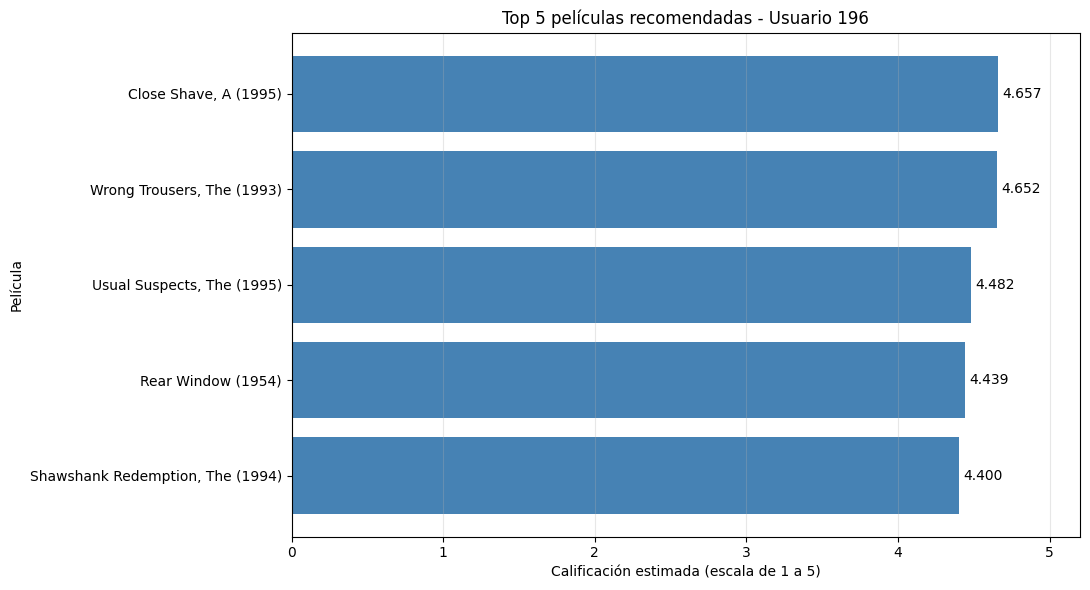

In [27]:
import matplotlib.pyplot as plt

# Ordenar para representar las recomendaciones
grafico_recomendaciones = top_5_recomendaciones.sort_values(
    "calificacion_estimada",
    ascending=True
)

plt.figure(figsize=(11, 6))

barras = plt.barh(
    grafico_recomendaciones["titulo"],
    grafico_recomendaciones["calificacion_estimada"],
    color="steelblue"
)

# Mostrar la calificación estimada
for barra in barras:
    valor = barra.get_width()

    plt.text(
        valor + 0.03,
        barra.get_y() + barra.get_height() / 2,
        f"{valor:.3f}",
        va="center"
    )

plt.title("Top 5 películas recomendadas - Usuario 196")
plt.xlabel("Calificación estimada (escala de 1 a 5)")
plt.ylabel("Película")
plt.xlim(0, 5.2)
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

Conclusiones del análisis de redes y sistemas de recomendación

1. Análisis exploratorio de los datos

Se analizaron 100.000 calificaciones correspondientes a 943 usuarios y 1.682 películas del conjunto MovieLens 100K. Se identificó una mayor concentración de calificaciones positivas, siendo 4 la puntuación más frecuente.

2. Análisis de redes

La representación bipartita permitió estudiar las relaciones entre usuarios y películas. Mediante el algoritmo Girvan-Newman se exploró la estructura de comunidades en una subred de 44 nodos y 295 aristas. Los resultados mostraron una comunidad predominante y nodos que se separaron progresivamente.

3. Comparación de modelos de recomendación

Se evaluaron los algoritmos SVD y KNN utilizando la métrica RMSE. En la evaluación inicial, SVD obtuvo un RMSE de 0,9352, inferior al 1,0194 de KNN, lo que indica un mejor desempeño predictivo de SVD en las condiciones evaluadas.

4. Optimización de hiperparámetros

Mediante GridSearchCV se optimizaron ambos modelos. SVD alcanzó un RMSE de prueba de 0,9348 y KNN obtuvo 0,9770. Aunque ambos mejoraron respecto a sus configuraciones iniciales, SVD mantuvo el menor error.

5. Recomendaciones personalizadas

Finalmente, se utilizó el modelo SVD optimizado para generar cinco recomendaciones al usuario 196. Las películas recomendadas obtuvieron calificaciones estimadas entre 4,40 y 4,66 sobre 5.

Conclusión general

Los resultados muestran que el análisis de redes permite explorar las relaciones entre usuarios y películas, mientras que los modelos de filtrado colaborativo permiten estimar preferencias individuales. En este estudio, SVD presentó el mejor desempeño predictivo entre los modelos evaluados, aunque sería necesario incorporar métricas adicionales para valorar directamente la calidad de las recomendaciones.